# Sightline: the data and the leakage

This notebook looks at the two drives and at why a shuffled frame split flatters a steering model. It
needs the dataset (`data/drive2018` and `data/drive2017`, checked with `sightline data verify`) and the
drives' caches (`sightline cache --drive drive2018`, then `--drive drive2017`). It reads them and the
committed reports, and writes nothing.

The text cells describe; every number is printed by a code cell. Where a committed report holds the same
value, the cell computes it again from the data and checks that the two agree. Angles are steering-wheel
degrees, positive when the wheel turns clockwise.

In [1]:
import io
import json
import math
import os
import sys
from pathlib import Path

import cv2
import numpy as np
from IPython.display import Image, Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.figure import Figure
from matplotlib.patches import Patch

# work from the repository root, wherever the notebook was opened
root = Path.cwd()
while not (root / "reports" / "leakage.json").is_file():
    if root == root.parent:
        raise FileNotFoundError("open this notebook inside the sightline repository (no reports/leakage.json found)")
    root = root.parent
os.chdir(root)
try:
    import sightline  # noqa: F401
except ModuleNotFoundError:  # not installed: use the source tree beside the reports
    sys.path.insert(0, str(root / "src"))
from sightline import figures
from sightline.data.cache import open_cache
from sightline.data.labels import load_labels, repair_dropouts
from sightline.data.splits import PUBLIC_NAMES, frames_sha256, make_split, paired_frames
from sightline.evaluate import TOLERANCES_DEG, within_key
from sightline.leakage import LOOKUP_PROTOCOLS, leakage_report, temporal_gaps
from sightline.paths import Workspace


def load(path):
    return json.loads(Path(path).read_text())


summary = load("reports/summary.json")
leak = load("reports/leakage.json")
legacy = load("reports/legacy.json")
runs = {path.stem: load(path) for path in sorted(Path("reports/runs").glob("*.json"))}
TRAIN_DRIVE = leak["drive"]
DRIVES = tuple(sorted(summary["drives"], key=lambda name: name != TRAIN_DRIVE))  # the training drive first

workspace = Workspace()  # data/ and runs/ under the repository root
raw, labels, cache = {}, {}, {}
for name in DRIVES:
    raw[name] = load_labels(workspace.drive(name))  # the label file as recorded
    labels[name] = repair_dropouts(raw[name])  # sensor dropouts repaired, as training and evaluation use them
    cache[name] = open_cache(labels[name], workspace.cache_dir(name))  # the model inputs, checked against the labels
    print(f"{name}: {len(labels[name]):,} labelled frames; its cache matches its label file")

SPLIT_COLOURS = {"dropped": "#e6e4dc", "training": "#4f6d8a", "validation": "#e0a030", "test": "#c8414b"}
DRIVE_COLOURS = dict(zip(DRIVES, (figures.INK, "#e0a030")))


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + " --- |" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def show(fig, fmt="png"):
    buffer = io.BytesIO()
    options = {"metadata": {"Software": None}} if fmt == "png" else {"pil_kwargs": {"quality": 82}}
    fig.savefig(buffer, format=fmt, dpi=fig.dpi, facecolor=fig.get_facecolor(), **options)
    display(Image(buffer.getvalue(), format=fmt))


def axes(fig, *args):
    ax = fig.add_subplot(*args)
    ax.set_facecolor(figures.SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8, colors=figures.INK_SECONDARY)
    return ax


def same(a, b):
    # equal, floats within rounding
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same(a[k], b[k]) for k in a)
    if isinstance(a, list):
        return isinstance(b, list) and len(a) == len(b) and all(same(x, y) for x, y in zip(a, b))
    if isinstance(a, float) and isinstance(b, (int, float)):
        return math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)
    return a == b

drive2018: 63,825 labelled frames; its cache matches its label file
drive2017: 45,406 labelled frames; its cache matches its label file


## The drives

Two drives from the Sully Chen driving datasets, recorded on different days. `drive2018` carries a
timestamp on every frame; `drive2017` carries none. Every run trains on `drive2018`; `drive2017` is the
other day.

| drive | frames | length | recorded angles (deg) | mean \|angle\| (deg) | median \|angle\| (deg) | frames past half a turn |
| --- | --- | --- | --- | --- | --- | --- |
| drive2018 | 63,825 | 3,351.7 s, a frame every 57.0 ms (median) | -338.82 to 252.61 | 13.081 | 5.34 | 235 (0.368%) |
| drive2017 | 45,406 | no timestamps | -159.93 to 501.78 | 15.522 | 7.87 | 223 (0.491%) |

frame counts agree with reports/summary.json; frames past 180 deg with reports/legacy.json


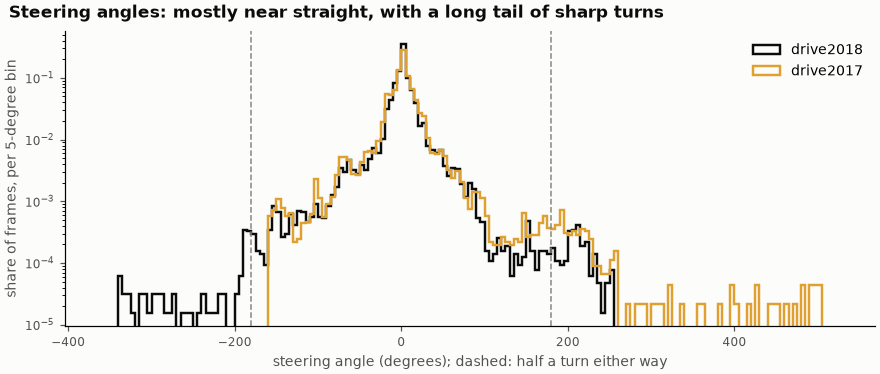

In [2]:
rows = []
for name in DRIVES:
    angles, recorded, stamps = labels[name].angles_deg, raw[name].angles_deg, raw[name].timestamps_s
    past = np.abs(cache[name].angles_deg) > 180
    length = ("no timestamps" if stamps is None
              else f"{stamps[-1] - stamps[0]:,.1f} s, a frame every {1000 * labels[name].median_dt_s():.1f} ms (median)")
    rows.append([name, f"{len(angles):,}", length, f"{recorded.min():.2f} to {recorded.max():.2f}",
                 f"{np.abs(angles).mean():.3f}", f"{np.median(np.abs(angles)):.2f}",
                 f"{past.sum()} ({past.mean():.3%})"])
table(["drive", "frames", "length", "recorded angles (deg)", "mean \\|angle\\| (deg)", "median \\|angle\\| (deg)",
       "frames past half a turn"], rows)
for name in DRIVES:
    assert summary["drives"][name]["frames"] == len(labels[name])
    assert legacy["atan_cap"]["labels_beyond_180"][name]["n"] == int((np.abs(cache[name].angles_deg) > 180).sum())
print("frame counts agree with reports/summary.json; frames past 180 deg with reports/legacy.json")

fig = Figure(figsize=(8.0, 3.4), dpi=110, facecolor=figures.SURFACE, layout="constrained")
ax = axes(fig)
bins = np.arange(-360, 530, 5)
for name in DRIVES:
    angles = labels[name].angles_deg
    ax.hist(angles, bins=bins, weights=np.full(angles.size, 1 / angles.size), histtype="step", linewidth=1.6,
            color=DRIVE_COLOURS[name], label=name)
for edge in (-180, 180):
    ax.axvline(edge, color=figures.MUTED, linewidth=1, linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("steering angle (degrees); dashed: half a turn either way", fontsize=9, color=figures.INK_SECONDARY)
ax.set_ylabel("share of frames, per 5-degree bin", fontsize=9, color=figures.INK_SECONDARY)
ax.legend(frameon=False, fontsize=9)
fig.suptitle("Steering angles: mostly near straight, with a long tail of sharp turns", x=0.01, ha="left",
             fontsize=11, fontweight="bold", color=figures.INK)
show(fig)

Most frames are close to straight ahead, which is why always steering straight ahead is a strong
baseline, and a few frames turn the wheel past half a turn, which an arctangent output head can never
reach.

### The segment profile

How hard the driving is changes along the drive. The next cell gives the mean absolute angle in each tenth
of `drive2018`. The busy, twisting middle and the calmer end matter for the later-in-the-drive split: it
trains on the start and tests on the end, so it measures a change of road as well as the model.

mean |angle| in each tenth of drive2018 (deg): 8.78, 7.69, 6.66, 28.35, 21.00, 23.54, 11.62, 7.10, 4.60, 11.47


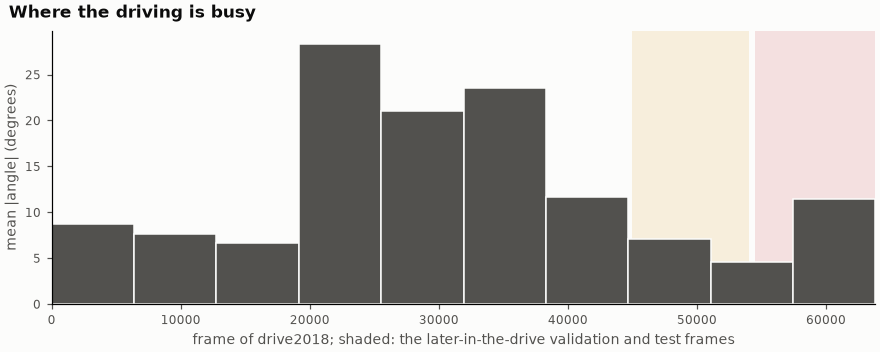

In [3]:
angles = np.abs(labels[TRAIN_DRIVE].angles_deg)
n = angles.size
edges = np.linspace(0, n, 11).astype(int)
tenths = [float(angles[a:b].mean()) for a, b in zip(edges[:-1], edges[1:])]
print(f"mean |angle| in each tenth of {TRAIN_DRIVE} (deg): " + ", ".join(f"{v:.2f}" for v in tenths))
settings = leak["splits"]
forward = make_split("forward", n, firewall=settings["firewall"], block=settings["block"])

fig = Figure(figsize=(8.0, 3.2), dpi=110, facecolor=figures.SURFACE, layout="constrained")
ax = axes(fig)
for part, colour in (("val", SPLIT_COLOURS["validation"]), ("test", SPLIT_COLOURS["test"])):
    frames = getattr(forward, part)
    ax.axvspan(frames[0], frames[-1], color=colour, alpha=0.15, linewidth=0)
ax.bar(edges[:-1], tenths, width=np.diff(edges), align="edge", color=figures.INK_SECONDARY, edgecolor=figures.SURFACE)
ax.set_xlim(0, n)
ax.set_xlabel(f"frame of {TRAIN_DRIVE}; shaded: the later-in-the-drive validation and test frames", fontsize=9,
              color=figures.INK_SECONDARY)
ax.set_ylabel("mean |angle| (degrees)", fontsize=9, color=figures.INK_SECONDARY)
fig.suptitle("Where the driving is busy", x=0.01, ha="left", fontsize=11, fontweight="bold", color=figures.INK)
show(fig)

## Sensor dropouts

Now and then the steering sensor reports exactly zero for a single frame in the middle of a turn and
then carries on. Trained on as they are, those frames teach a model to snap the wheel straight mid-turn.
A frame is repaired, with the mean of its two neighbours, only when its angle is exactly zero and both
neighbours are large and turn the same way; a genuine straight-ahead zero never meets that condition.
The cell shows the most striking dropout of each drive, before and after.

| drive | frames repaired | most striking dropout: frame | recorded: before, the frame, after | repaired angle |
| --- | --- | --- | --- | --- |
| drive2018 | 368 | 27,117 | 212.97, 0.00, 212.97 | 212.97 |
| drive2017 | 268 | 283 | 501.78, 0.00, 498.55 | 500.16 |

repair counts agree with reports/summary.json


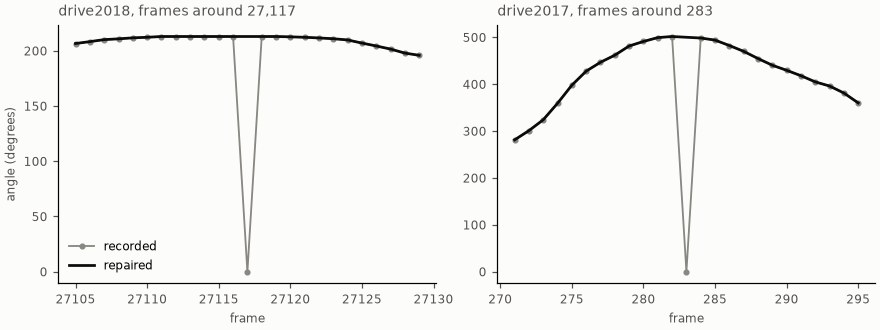

In [4]:
rows, examples = [], {}
for name in DRIVES:
    repaired, recorded = labels[name].repaired_indices, raw[name].angles_deg
    strength = np.minimum(np.abs(recorded[repaired - 1]), np.abs(recorded[repaired + 1]))
    k = int(repaired[np.argmax(strength)])
    examples[name] = k
    rows.append([name, f"{repaired.size}", f"{k:,}", ", ".join(f"{v:.2f}" for v in recorded[k - 1:k + 2]),
                 f"{labels[name].angles_deg[k]:.2f}"])
    assert summary["drives"][name]["repaired_labels"] == repaired.size
table(["drive", "frames repaired", "most striking dropout: frame", "recorded: before, the frame, after",
       "repaired angle"], rows)
print("repair counts agree with reports/summary.json")

fig = Figure(figsize=(8.0, 3.0), dpi=110, facecolor=figures.SURFACE, layout="constrained")
for j, name in enumerate(DRIVES):
    ax = axes(fig, 1, len(DRIVES), j + 1)
    k = examples[name]
    window = np.arange(k - 12, k + 13)
    ax.plot(window, raw[name].angles_deg[window], color=figures.MUTED, linewidth=1.2, marker="o", markersize=3,
            label="recorded")
    ax.plot(window, labels[name].angles_deg[window], color=figures.INK, linewidth=1.8, label="repaired")
    ax.set_title(f"{name}, frames around {k:,}", fontsize=9, color=figures.INK_SECONDARY, loc="left")
    ax.set_xlabel("frame", fontsize=8, color=figures.INK_SECONDARY)
    if j == 0:
        ax.set_ylabel("angle (degrees)", fontsize=8, color=figures.INK_SECONDARY)
        ax.legend(frameon=False, fontsize=8)
show(fig)

## The three splits, drawn along the drive

Each row is the whole of `drive2018`, frame by frame, coloured by the set the frame belongs to. The
shuffled split interleaves the sets frame by frame, so its whole-drive row looks like noise; the second
row zooms into a few seconds of it. The blocked split deals out long blocks and drops a band of frames at
every boundary between training and evaluation; the later-in-the-drive split cuts the drive into three
pieces with the same bands. The cell also checks the splits against the run reports, and finds the paired
frames: the test frames the shuffled split and the blocked split have in common.

shuffled: 44,677 training, 9,574 validation, 9,574 test frames, 0 dropped
blocked: 39,825 training, 6,000 validation, 6,000 test frames, 12,000 dropped
later in the drive: 44,427 training, 9,074 validation, 9,324 test frames, 1,000 dropped
split sizes agree with the seed-0 run reports
paired frames: 893; the same frames as reports/leakage.json and the run reports: True


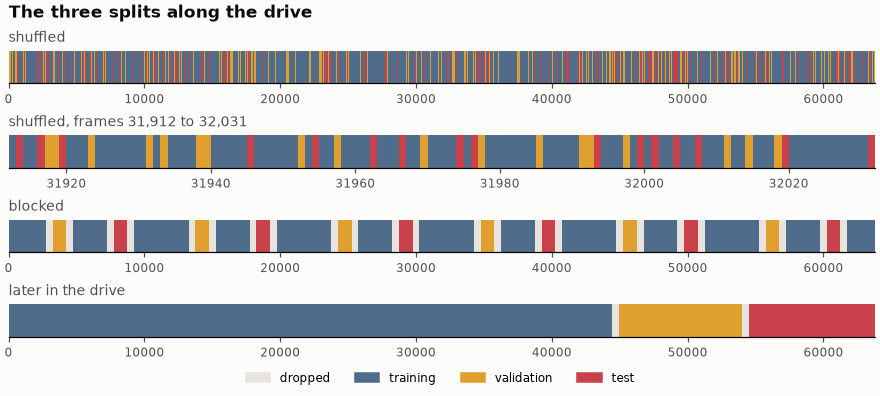

In [5]:
splits = {p: make_split(p, n, seed=leak["seed"], firewall=settings["firewall"], block=settings["block"])
          for p in ("leaky", "blocked", "forward")}
for protocol, split in splits.items():
    sizes = runs[f"{TRAIN_DRIVE}_sightlinenet_{protocol}_s{leak['seed']}"]["splits"]
    assert (split.train.size, split.val.size, split.test.size) == (sizes["train_n"], sizes["val_n"], sizes["test_n"])
    print(f"{PUBLIC_NAMES[protocol]}: {split.train.size:,} training, {split.val.size:,} validation, "
          f"{split.test.size:,} test frames, {n - split.train.size - split.val.size - split.test.size:,} dropped")
print(f"split sizes agree with the seed-{leak['seed']} run reports")

paired = paired_frames(splits["blocked"], splits["leaky"])
digests = {runs[f"{TRAIN_DRIVE}_{model}_{protocol}_s{leak['seed']}"]["paired"]["frames_sha256"]
           for model in ("sightlinenet", "pilotnet") for protocol in ("leaky", "blocked")}
print(f"paired frames: {paired.size}; the same frames as reports/leakage.json and the run reports: "
      f"{digests == {frames_sha256(paired)} == {leak['paired']['frames_sha256']}}")


def codes(split, frames):
    row = np.zeros(frames.size, np.uint8)
    for value, part in ((1, split.train), (2, split.val), (3, split.test)):
        row[np.isin(frames, part)] = value
    return row


everything = np.arange(n)
zoom = np.arange(n // 2, n // 2 + 120)
rows = [("shuffled", codes(splits["leaky"], everything), everything),
        (f"shuffled, frames {zoom[0]:,} to {zoom[-1]:,}", codes(splits["leaky"], zoom), zoom),
        ("blocked", codes(splits["blocked"], everything), everything),
        ("later in the drive", codes(splits["forward"], everything), everything)]
cmap = ListedColormap(list(SPLIT_COLOURS.values()))
fig = Figure(figsize=(8.0, 3.6), dpi=110, facecolor=figures.SURFACE, layout="constrained")
for j, (title, row, frames) in enumerate(rows):
    ax = axes(fig, len(rows), 1, j + 1)
    ax.imshow(row[None, :], aspect="auto", cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest",
              extent=(frames[0], frames[-1] + 1, 0, 1))
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_title(title, fontsize=9, loc="left", color=figures.INK_SECONDARY)
fig.legend(handles=[Patch(color=c, label=label) for label, c in SPLIT_COLOURS.items()], loc="outside lower center",
           ncols=4, frameon=False, fontsize=8)
fig.suptitle("The three splits along the drive", x=0.01, ha="left", fontsize=11, fontweight="bold", color=figures.INK)
show(fig)

## How far is the nearest training frame?

For every validation and test frame, the distance in frames to the nearest training frame. Under the
shuffled split it is nearly always the very next frame of the video; the blocked and later-in-the-drive
splits keep every evaluation frame far from training by construction. The last column turns the median
into seconds with the drive's median frame interval: a distance expressed in time, not a time measured
between two frames. The lines under the table measure that time for the blocked split, from the drive's
timestamps: how far its closest validation frame and its closest test frame are from a training frame.
The frame interval varies along the drive, so that time is not the distance in frames times the median
interval.

| split | frames | closest (frames) | median (frames) | 95th percentile (frames) | next to a training frame | median x median interval (s) |
| --- | --- | --- | --- | --- | --- | --- |
| shuffled | validation | 1 | 1 | 2.0 | 91.1% | 0.057 |
| shuffled | test | 1 | 1 | 2.0 | 90.9% | 0.057 |
| blocked | validation | 501 | 750.5 | 975.1 | 0.0% | 42.778 |
| blocked | test | 501 | 750.5 | 975.1 | 0.0% | 42.778 |
| later in the drive | validation | 501 | 5,037.5 | 9,120.4 | 0.0% | 287.137 |
| later in the drive | test | 10,075 | 14,736.5 | 18,931.8 | 0.0% | 839.979 |

computed again from the splits: the same as reports/leakage.json
blocked validation frames: the closest to a training frame by the drive's timestamps is frame 35,749, 24.3 s from training frame 36,250 (501 frames away)
blocked test frames: the closest to a training frame by the drive's timestamps is frame 61,249, 24.6 s from training frame 61,750 (501 frames away)


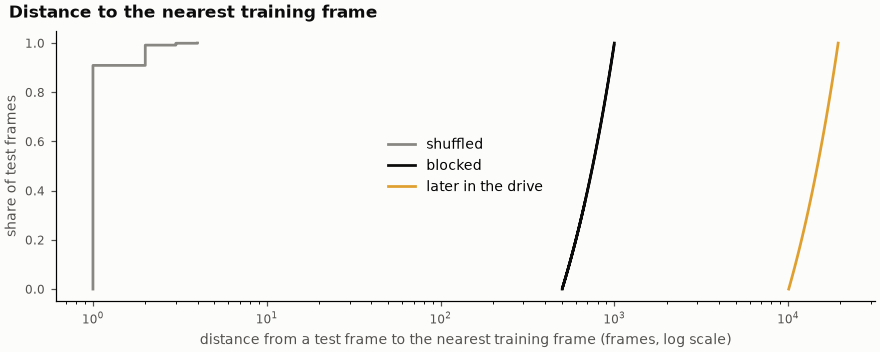

In [6]:
dt = labels[TRAIN_DRIVE].median_dt_s()
rows, gaps = [], {}
for protocol, split in splits.items():
    for which, title in (("val", "validation"), ("test", "test")):
        mine = temporal_gaps(split, which, dt)
        assert same(mine, leak["gaps"][protocol][which])
        rows.append([PUBLIC_NAMES[protocol], title, f"{mine['min_frames']:,}", f"{mine['median_frames']:,g}",
                     f"{mine['p95_frames']:,.1f}", f"{mine['frac_within_1']:.1%}", f"{mine['median_s']:,.3f}"])
    train = np.sort(split.train)
    pos = np.searchsorted(train, split.test)
    gaps[protocol] = np.minimum(np.abs(split.test - train[np.maximum(pos - 1, 0)]),
                                np.abs(train[np.minimum(pos, train.size - 1)] - split.test))
table(["split", "frames", "closest (frames)", "median (frames)", "95th percentile (frames)",
       "next to a training frame", "median x median interval (s)"], rows)
print("computed again from the splits: the same as reports/leakage.json")

# the blocked split's closest evaluation frames in seconds, from the drive's own timestamps: the frame
# interval varies along the drive, so a distance in frames times the median interval is not the time apart
stamps = labels[TRAIN_DRIVE].timestamps_s
assert np.all(np.diff(stamps) >= 0), "timestamps out of order: the nearest frame in time may not be a neighbour"
trained = np.sort(splits["blocked"].train)
for which, title in (("val", "validation"), ("test", "test")):
    held = np.sort(getattr(splits["blocked"], which))
    pos = np.searchsorted(trained, held)
    near = np.stack([trained[np.maximum(pos - 1, 0)], trained[np.minimum(pos, trained.size - 1)]])
    apart = np.abs(stamps[near] - stamps[held])  # to the training frame before it and the one after
    k = int(np.argmin(apart.min(axis=0)))
    closest = int(near[np.argmin(apart[:, k]), k])
    print(f"blocked {title} frames: the closest to a training frame by the drive's timestamps is frame "
          f"{int(held[k]):,}, {apart[:, k].min():.1f} s from training frame {closest:,} "
          f"({abs(closest - int(held[k])):,} frames away)")

fig = Figure(figsize=(8.0, 3.2), dpi=110, facecolor=figures.SURFACE, layout="constrained")
ax = axes(fig)
for protocol, colour in zip(gaps, (figures.MUTED, figures.INK, SPLIT_COLOURS["validation"])):
    values = np.sort(gaps[protocol])
    ax.step(values, np.arange(1, values.size + 1) / values.size, where="post", color=colour, linewidth=1.8,
            label=PUBLIC_NAMES[protocol])
ax.set_xscale("log")
ax.set_xlabel("distance from a test frame to the nearest training frame (frames, log scale)", fontsize=9,
              color=figures.INK_SECONDARY)
ax.set_ylabel("share of test frames", fontsize=9, color=figures.INK_SECONDARY)
ax.legend(frameon=False, fontsize=9, loc="center")
fig.suptitle("Distance to the nearest training frame", x=0.01, ha="left", fontsize=11, fontweight="bold",
             color=figures.INK)
show(fig)

## What the nearest training frame looks like

The next cell runs the whole leakage analysis again from the drive's cache and checks it against
`reports/leakage.json`. For each paired test frame it finds the training frame that looks most like it
under each split, comparing small grayscale versions of the model's input by pixel RMSE (grey levels). A
handful of example frames, chosen by how hard the human steers on them, from straight to the sharpest
turn, are shown with both neighbours.

the analysis run again from the cache matches reports/leakage.json: True


| test frame | its angle | shuffled: nearest training frame | frames apart | time apart | pixel RMSE | its angle | blocked: nearest training frame | frames apart | time apart | pixel RMSE | its angle |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 7,917 | +0.40 | 7,916 | 1 | 0.041 s | 8.79 | +0.50 | 28,219 | 20,302 | 17.9 min | 28.47 | +1.41 |
| 8,470 | +3.53 | 8,469 | 1 | 0.057 s | 14.13 | +3.43 | 28,187 | 19,717 | 17.4 min | 27.30 | +0.81 |
| 8,173 | +6.96 | 8,174 | 1 | 0.057 s | 12.41 | +7.56 | 6,157 | 2,016 | 1.8 min | 32.29 | -85.31 |
| 29,273 | +15.53 | 29,274 | 1 | 0.039 s | 7.54 | +15.53 | 31,160 | 1,887 | 1.7 min | 31.69 | +45.78 |
| 60,875 | +76.64 | 60,874 | 1 | 0.043 s | 5.13 | +71.80 | 57,834 | 3,041 | 2.5 min | 29.52 | +17.55 |
| 60,913 | +234.35 | 60,912 | 1 | 0.030 s | 14.15 | +234.25 | 21,414 | 39,499 | 34.4 min | 46.88 | -337.11 |

time apart: from the two frames' timestamps; angles in degrees


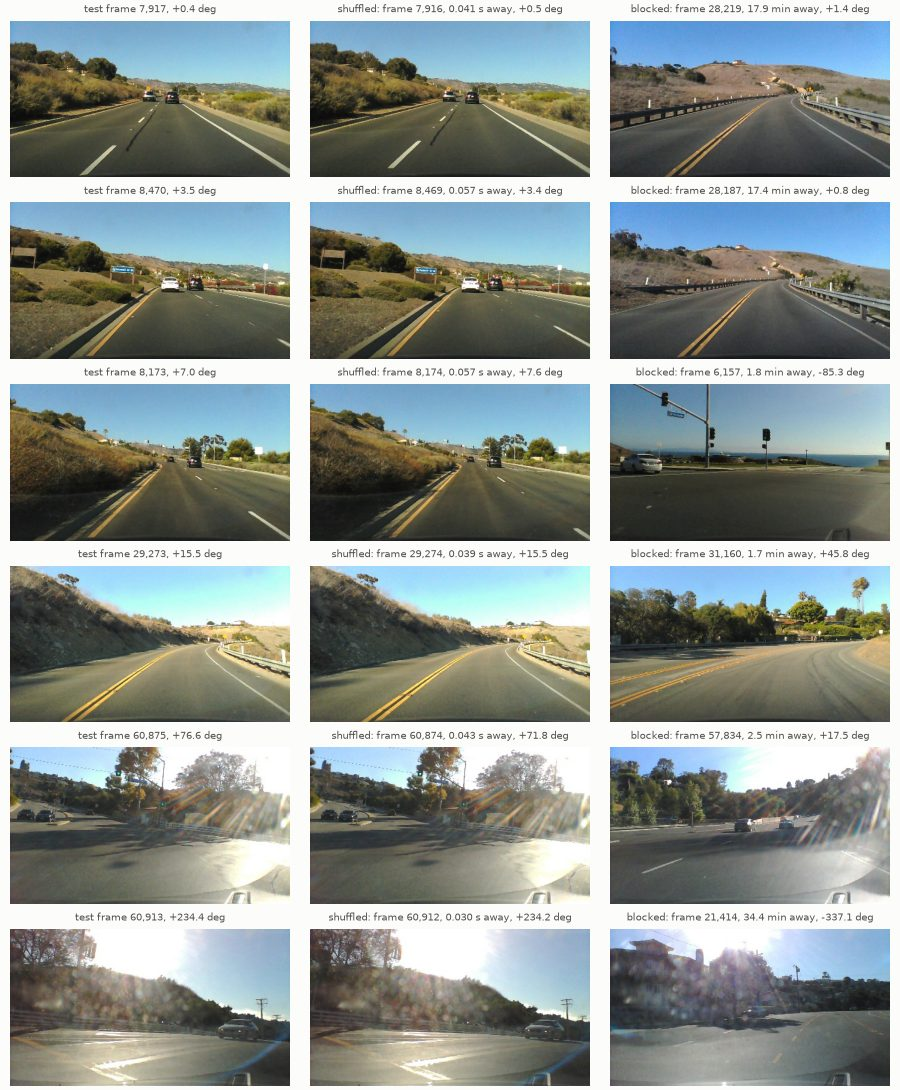

In [7]:
fresh = leakage_report(cache[TRAIN_DRIVE], drive=TRAIN_DRIVE, seed=leak["seed"],
                       timestamps_s=labels[TRAIN_DRIVE].timestamps_s, firewall=settings["firewall"],
                       block=settings["block"])
print(f"the analysis run again from the cache matches reports/leakage.json: {same(fresh, leak)}")

rows = []
for p in leak["pairs"]:
    s, b = p["leaky"], p["blocked"]
    rows.append([f"{p['frame']:,}", f"{p['angle_deg']:+.2f}",
                 f"{s['nn_frame']:,}", f"{s['gap_frames']:,}", f"{s['gap_s']:.3f} s", f"{s['pixel_rmse']:.2f}",
                 f"{s['nn_angle_deg']:+.2f}",
                 f"{b['nn_frame']:,}", f"{b['gap_frames']:,}", f"{b['gap_s'] / 60:.1f} min", f"{b['pixel_rmse']:.2f}",
                 f"{b['nn_angle_deg']:+.2f}"])
table(["test frame", "its angle", "shuffled: nearest training frame", "frames apart", "time apart", "pixel RMSE",
       "its angle", "blocked: nearest training frame", "frames apart", "time apart", "pixel RMSE", "its angle"], rows)
print("time apart: from the two frames' timestamps; angles in degrees")


def camera(frame):
    return cv2.cvtColor(cv2.imread(str(labels[TRAIN_DRIVE].frame_path(frame))), cv2.COLOR_BGR2RGB)


fig = Figure(figsize=(9.0, 1.75 * len(leak["pairs"]) + 0.4), dpi=100, facecolor=figures.SURFACE, layout="constrained")
for j, p in enumerate(leak["pairs"]):
    s, b = p["leaky"], p["blocked"]
    panels = [(p["frame"], f"test frame {p['frame']:,}, {p['angle_deg']:+.1f} deg"),
              (s["nn_frame"], f"shuffled: frame {s['nn_frame']:,}, {s['gap_s']:.3f} s away, {s['nn_angle_deg']:+.1f} deg"),
              (b["nn_frame"], f"blocked: frame {b['nn_frame']:,}, {b['gap_s'] / 60:.1f} min away, {b['nn_angle_deg']:+.1f} deg")]
    for i, (frame, title) in enumerate(panels):
        ax = fig.add_subplot(len(leak["pairs"]), 3, 3 * j + i + 1)
        ax.imshow(camera(frame))
        ax.set_axis_off()
        ax.set_title(title, fontsize=7.5, color=figures.INK_SECONDARY)
show(fig, "jpeg")

Under the shuffled split, the most similar training frame is the next or the previous frame of the
video: practically the same picture with practically the same steering angle. Under the blocked split it
comes from somewhere else on the drive, minutes away, and often steers differently.

## A predictor with no model at all

The memoriser finds the most similar training frame and copies its steering angle. It learns nothing
about roads. It is scored on the paired frames, which both splits hold out for testing, so both rows of
the table are measured on identical frames; the second table puts it beside the trained models of the
same seed on the same frames.

In [8]:
rows = []
for protocol in LOOKUP_PROTOCOLS:
    m = leak["memoriser"][protocol]
    rows.append([PUBLIC_NAMES[protocol], f"{m['n']}", f"{m['mae_deg']:.3f}", f"{m['rmse_deg']:.2f}",
                 f"{m['medae_deg']:.2f}", *(f"{m[within_key(x)]:.1%}" for x in TOLERANCES_DEG),
                 f"{m['median_gap_frames']:,g}", f"{m['median_pixel_rmse']:.2f}"])
# one column per tolerance the evaluation code gives a share of frames within
table(["training frames searched", "frames", "MAE (deg)", "RMSE", "median error",
       *(f"within {x:g} deg" for x in TOLERANCES_DEG), "median distance to the copied frame (frames)",
       "median pixel RMSE"], rows)

scores, zero = [(f"memoriser, {PUBLIC_NAMES[p]} split", leak["memoriser"][p]["mae_deg"]) for p in LOOKUP_PROTOCOLS], set()
for model, entry in summary["paired_leakage"].items():
    (seed,) = [p for p in entry["per_seed"] if p["seed"] == leak["seed"]]
    scores += [(f"{figures.MODEL_LABELS[model]} trained on shuffled frames", seed["shuffled_mae_deg"]),
               (f"{figures.MODEL_LABELS[model]} trained on blocked frames", seed["blocked_mae_deg"])]
    zero.add(seed["zero_mae_deg"])
(zero,) = zero  # the same frames for every model
scores.append(("always straight ahead", zero))
table(["predictor", f"MAE on the {leak['paired']['n']} paired frames of seed {leak['seed']} (deg)"],
      [[name, f"{value:.2f}"] for name, value in sorted(scores, key=lambda item: item[1])])

| training frames searched | frames | MAE (deg) | RMSE | median error | within 1.5 deg | within 5 deg | within 15 deg | median distance to the copied frame (frames) | median pixel RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| shuffled | 893 | 0.638 | 2.03 | 0.10 | 90.4% | 97.5% | 99.7% | 1 | 9.58 |
| blocked | 893 | 21.868 | 45.21 | 8.47 | 18.1% | 40.0% | 64.9% | 12,091 | 30.60 |

| predictor | MAE on the 893 paired frames of seed 0 (deg) |
| --- | --- |
| memoriser, shuffled split | 0.64 |
| SightlineNet trained on shuffled frames | 2.98 |
| PilotNet trained on shuffled frames | 4.03 |
| SightlineNet trained on blocked frames | 11.17 |
| PilotNet trained on blocked frames | 13.39 |
| always straight ahead | 17.31 |
| memoriser, blocked split | 21.87 |

Under the shuffled split, copying the angle of a near-identical neighbouring frame beats every trained
model, with no understanding of the road at all. Under the blocked split the same lookup is worse than
steering straight ahead. A shuffled test set rewards remembering the frames next door; the blocked split
does not, which is why it is the split the results stand on (`02-results.ipynb`).